# 10 — Stealing-Guided Synonym Substitution: V1 Support Sweep

**Question:** how does the minimum frequency support change dictionary coverage and watermark-removal effectiveness?

This notebook extends the original notebook 10 **without overwriting any existing results**. We compare **`MIN_SUPPORT = 2, 5, 10, 15`** while preserving:

- 10 fixed stratified splits: 400 matched WM/NoWM training pairs and 200 held-out WM texts per split.
- Five **nominal** word-replacement ratios: `0.1, 0.2, 0.3, 0.4, 0.5`.
- Four methods: `markllm`, `guided`, `random_synonyms_guided_positions`, `fully_random`.
- The original log-frequency ratio, smoothing `ALPHA=0.5`, WordNet candidates and detector.
- The same split seeds and random seeds **across support thresholds**, to support paired comparisons.

**Expected size:** 4 support thresholds × 10 splits × 5 ratios × 200 texts × 4 methods = **160,000 result rows**, including precomputed MarkLLM results reused from notebook 05. New detector evaluations are cached for interrupted-run recovery.

**Fairness:** At a given support/split/ratio/text, the three custom methods have the **same actual count of word substitutions**. This count can change with support. MarkLLM is an external baseline at the same nominal ratio only; its effective word-edit count is not guaranteed identical.

**Exploratory analysis:** previous tests informed this experiment; splits overlap and are not independent experiments. No automatic claim of statistical significance or semantic preservation.

## 1. Setup and configuration

In [1]:
import hashlib
import json
import math
import random
import re
import sys
import time
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import wordnet
from tqdm import tqdm


def find_project_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "src" / "detection.py").is_file() and (
            folder / "results" / "Cleaned Data"
        ).is_dir():
            return folder
    raise FileNotFoundError("Cannot locate project root from current working directory.")


ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT / "src"))
from detection import detect, load_detector, load_jsonl, save_jsonl

SPLIT_SEEDS = [42, 100, 101, 102, 103, 104, 105, 106, 107, 108]
RATIOS = [0.1, 0.2, 0.3, 0.4, 0.5]
MIN_SUPPORTS = [2, 5, 10, 15]
ALPHA = 0.5
ATTACK_VERSION = "v1_word_unigrams_multi_support_2026_11"
METHODS = ["markllm", "guided", "random_synonyms_guided_positions", "fully_random"]

OUT_DIR = (ROOT / "results" / "attacks"
           / "stealing_guided_v1_improvements" / "support_sweep_2_5_10_15")
SPLITS_DIR = OUT_DIR / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
OLD_SUPPORT10_DIR = (ROOT / "results" / "attacks"
                     / "stealing_guided_v1_improvements" / "ratio_sweep_support10")

WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")
try:
    wordnet.synsets("important")
except LookupError as exc:
    raise RuntimeError("NLTK WordNet corpus missing; install WordNet in your local venv.") from exc

print("Project:", ROOT)
print("Output:", OUT_DIR)
print("Supports:", MIN_SUPPORTS, "| splits:", len(SPLIT_SEEDS), "| ratios:", RATIOS)

Project: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Output: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15
Supports: [2, 5, 10, 15] | splits: 10 | ratios: [0.1, 0.2, 0.3, 0.4, 0.5]


## 2. Load and validate paired datasets / existing MarkLLM results

In [2]:
WM_PATH = ROOT / "results" / "Cleaned Data" / "watermarked_600.jsonl"
NOWM_PATH = ROOT / "results" / "Cleaned Data" / "unwatermarked_600.jsonl"
BASELINE_PATH = ROOT / "results" / "attacks" / "baseline_original.jsonl"
SYN_DIR = ROOT / "results" / "attacks" / "synonym_substitution"

wm = load_jsonl(WM_PATH)
no_wm = load_jsonl(NOWM_PATH)
baseline_rows = load_jsonl(BASELINE_PATH)
assert len(wm) == len(no_wm) == len(baseline_rows) == 600

baseline_by_idx = {int(row["idx"]): row for row in baseline_rows}
assert set(baseline_by_idx) == set(range(600)), "Baseline indices must be 0..599."


def dataset_id(row):
    return row["dataset_name"].split("_batch_")[0]


groups = defaultdict(list)
for idx in range(600):
    assert wm[idx]["prompt"] == no_wm[idx]["prompt"]
    assert wm[idx]["prompt"] == baseline_by_idx[idx]["prompt"]
    assert dataset_id(wm[idx]) == dataset_id(no_wm[idx])
    assert wm[idx]["completion"] and no_wm[idx]["completion"]
    groups[dataset_id(wm[idx])].append(idx)

assert len(groups) == 3 and sorted(map(len, groups.values())) == [200, 200, 200], (
    f"Expected three datasets with 200 prompts each, got: "
    f"{ {k: len(v) for k, v in groups.items()} }"
)

markllm_by_ratio = {}
markllm_paths = {}
for ratio in RATIOS:
    path = SYN_DIR / f"synonym_substitution_r{ratio:.1f}.jsonl"
    assert path.is_file(), f"Missing MarkLLM baseline: {path}"
    records = load_jsonl(path)
    lookup = {int(row["idx"]): row for row in records}
    assert len(records) == len(lookup) == 600
    assert set(lookup) == set(range(600))
    for idx in range(600):
        record = lookup[idx]
        assert record["original"] == wm[idx]["completion"], (ratio, idx)
        assert bool(record["original_detected"]) == bool(baseline_by_idx[idx]["detected"])
        assert abs(float(record["ratio"]) - ratio) < 1e-9
    markllm_by_ratio[ratio] = lookup
    markllm_paths[ratio] = path

print("Dataset sizes:", {k: len(v) for k, v in sorted(groups.items())})
print("Baseline originally detected:", sum(bool(r["detected"]) for r in baseline_rows), "/600")
print("MarkLLM records verified:", len(RATIOS), "ratios x 600 responses")

Dataset sizes: {'2-1_longform_qa': 200, '2-2_finance_qa': 200, '5-1_alpacafarm': 200}
Baseline originally detected: 583 /600
MarkLLM records verified: 5 ratios x 600 responses


## 3. Lock the configuration and data fingerprints

In [3]:
def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


input_paths = [WM_PATH, NOWM_PATH, BASELINE_PATH, ROOT / "src" / "detection.py"]
input_paths.extend(markllm_paths[r] for r in RATIOS)
input_sha256 = {str(p.relative_to(ROOT)): file_sha256(p) for p in input_paths}
config = {
    "attack_version": ATTACK_VERSION,
    "split_seeds": SPLIT_SEEDS,
    "ratios": RATIOS,
    "min_supports": MIN_SUPPORTS,
    "alpha": ALPHA,
    "methods": METHODS,
    "input_sha256": input_sha256,
}
config_path = OUT_DIR / "config.json"
if config_path.exists():
    saved_config = json.loads(config_path.read_text(encoding="utf-8"))
    if saved_config != config:
        raise RuntimeError("Experiment configuration or inputs changed. Use a new output directory.")
    print("Existing configuration matches: OK")
else:
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
    print("Configuration saved:", config_path)

# Reuse existing support-10 checkpoints only when input fingerprints/configuration match.
old_config_path = OLD_SUPPORT10_DIR / "config.json"
REUSE_SUPPORT10 = False
if old_config_path.is_file():
    old_config = json.loads(old_config_path.read_text(encoding="utf-8"))
    REUSE_SUPPORT10 = (
        old_config.get("min_support") == 10
        and old_config.get("alpha") == ALPHA
        and old_config.get("ratios") == RATIOS
        and old_config.get("split_seeds") == SPLIT_SEEDS
        and old_config.get("methods") == METHODS
        and old_config.get("input_sha256") == input_sha256
        and old_config.get("attack_version") == "word_unigrams_v1_ratio_sweep_2026_11"
    )
print("Compatible old support-10 checkpoints:", REUSE_SUPPORT10)

Configuration saved: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/config.json
Compatible old support-10 checkpoints: True


## 4. Stratified train/test splits and statistical word dictionaries

In [4]:
def make_split(seed: int):
    rng = random.Random(seed)
    train, test = [], []
    for j, (_, original_indices) in enumerate(sorted(groups.items())):
        indices = original_indices.copy()
        rng.shuffle(indices)
        n_train = 134 if j == 0 else 133
        train.extend(indices[:n_train])
        test.extend(indices[n_train:])
    train, test = sorted(train), sorted(test)
    assert len(train) == 400 and len(test) == 200
    assert not set(train).intersection(test)
    assert set(train).union(test) == set(range(600))
    return train, test


def tokenize_words(text: str):
    return WORD_PATTERN.findall(text.lower())


@lru_cache(maxsize=None)
def get_synonyms(word: str):
    """Single-word WordNet lemmas, exactly as in the original notebook 10."""
    candidates = set()
    for synset in wordnet.synsets(word):
        for lemma in synset.lemmas():
            candidate = lemma.name().lower()
            if candidate != word and re.fullmatch(r"[a-z]+", candidate):
                candidates.add(candidate)
    return tuple(sorted(candidates))


def learn_word_statistics(training_indices):
    wm_counts, nowm_counts = Counter(), Counter()
    for idx in training_indices:
        wm_counts.update(tokenize_words(wm[idx]["completion"]))
        nowm_counts.update(tokenize_words(no_wm[idx]["completion"]))

    vocabulary = set(wm_counts) | set(nowm_counts)
    v = len(vocabulary)
    total_wm = sum(wm_counts.values())
    total_nowm = sum(nowm_counts.values())
    scores = {
        word: math.log(
            ((wm_counts[word] + ALPHA) / (total_wm + ALPHA * v))
            / ((nowm_counts[word] + ALPHA) / (total_nowm + ALPHA * v))
        )
        for word in vocabulary
    }
    return wm_counts, nowm_counts, scores


def build_dictionary(statistics, min_support: int):
    wm_counts, nowm_counts, scores = statistics
    vocabulary = set(scores)
    dictionary = {}
    for word in sorted(vocabulary):
        if wm_counts[word] + nowm_counts[word] < min_support:
            continue
        if scores[word] <= 0:
            continue
        candidates = [
            candidate for candidate in get_synonyms(word)
            if candidate in scores
            and wm_counts[candidate] + nowm_counts[candidate] >= min_support
            and scores[candidate] < scores[word]
        ]
        if candidates:
            best = min(candidates, key=lambda s: scores[s])
            dictionary[word] = {
                "replacement": best,
                "gain": scores[word] - scores[best],
            }
    return dictionary


train_42, test_42 = make_split(42)
statistics_42 = learn_word_statistics(train_42)
dictionaries_42 = {s: build_dictionary(statistics_42, s) for s in MIN_SUPPORTS}
assert all(len(dictionaries_42[a]) >= len(dictionaries_42[b])
           for a, b in zip(MIN_SUPPORTS, MIN_SUPPORTS[1:]))
assert sum(bool(baseline_by_idx[i]["detected"]) for i in test_42) == 195
print("Seed 42 | train:", len(train_42), "| test:", len(test_42))
print("Seed 42 | dictionary sizes:", {s: len(d) for s, d in dictionaries_42.items()})
print("Seed 42 | detected originally in test: 195")

Seed 42 | train: 400 | test: 200
Seed 42 | dictionary sizes: {2: 1596, 5: 964, 10: 554, 15: 379}
Seed 42 | detected originally in test: 195


## 5. Attack implementations — unchanged from notebook 10

In [5]:
def apply_substitutions(text: str, selected):
    """Apply character-span replacements right-to-left, preserving basic casing."""
    attacked = text
    for item in sorted(selected, key=lambda x: x["start"], reverse=True):
        original = attacked[item["start"]:item["end"]]
        replacement = item["replacement"]
        if original.isupper():
            replacement = replacement.upper()
        elif original.istitle():
            replacement = replacement.capitalize()
        attacked = attacked[:item["start"]] + replacement + attacked[item["end"]:]
    return attacked


def guided_attack(text: str, dictionary: dict, ratio: float):
    matches = list(WORD_PATTERN.finditer(text.lower()))
    candidates = []
    for match in matches:
        word = match.group()
        if word in dictionary:
            candidates.append({
                "start": match.start(), "end": match.end(),
                "original": word,
                "replacement": dictionary[word]["replacement"],
                "gain": dictionary[word]["gain"],
            })
    candidates.sort(key=lambda x: x["gain"], reverse=True)
    target = round(len(matches) * ratio)
    selected = candidates[:target]
    return {
        "attacked": apply_substitutions(text, selected),
        "n_words": len(matches),
        "n_targeted": target,
        "n_replaced": len(selected),
        "substitutions": selected,
    }


def random_synonyms_same_positions(text: str, guided_result: dict, seed: int):
    rng = random.Random(seed)
    selected = []
    for item in guided_result["substitutions"]:
        synonyms = get_synonyms(item["original"])
        assert synonyms, f"WordNet synonyms missing for {item['original']}"
        selected.append({
            "start": item["start"], "end": item["end"],
            "original": item["original"],
            "replacement": rng.choice(synonyms),
        })
    return {
        "attacked": apply_substitutions(text, selected),
        "n_words": guided_result["n_words"],
        "n_targeted": guided_result["n_targeted"],
        "n_replaced": len(selected),
        "substitutions": selected,
    }


def fully_random_attack(text: str, n_replacements: int, ratio: float, seed: int):
    rng = random.Random(seed)
    matches = list(WORD_PATTERN.finditer(text.lower()))
    candidates = []
    for match in matches:
        word = match.group()
        synonyms = get_synonyms(word)
        if synonyms:
            candidates.append({
                "start": match.start(), "end": match.end(),
                "original": word, "synonyms": synonyms,
            })

    if n_replacements > len(candidates):
        raise RuntimeError(
            f"Only {len(candidates)} random candidate positions for {n_replacements} edits."
        )
    sampled = rng.sample(candidates, n_replacements)
    selected = [{
        "start": item["start"], "end": item["end"],
        "original": item["original"],
        "replacement": rng.choice(item["synonyms"]),
    } for item in sampled]

    return {
        "attacked": apply_substitutions(text, selected),
        "n_words": len(matches),
        "n_targeted": round(len(matches) * ratio),
        "n_replaced": len(selected),
        "substitutions": selected,
    }

## 6. Sanity checks and original V1 reproduction (support 10)

In [6]:
# The original seed-42, ratio-0.1 guided texts MUST be identical at support=10.
original_guided_file = (ROOT / "results" / "attacks" / "stealing_guided"
                        / "stealing_guided_r0.1.jsonl")
if original_guided_file.is_file():
    old_guided = {int(r["idx"]): r for r in load_jsonl(original_guided_file)}
    assert set(old_guided) == set(test_42)
    mismatches = [
        idx for idx in test_42
        if guided_attack(wm[idx]["completion"], dictionaries_42[10], 0.1)["attacked"]
        != old_guided[idx]["attacked"]
    ]
    assert not mismatches, f"Support=10 differs from notebook 09: {mismatches[:5]}"
    print("Support=10 reproduces notebook 09: 200/200 attacked texts matched.")
else:
    print("Original notebook 09 output not present (optional consistency check skipped).")

# Ensure budget matches for all custom attacks in all support variants.
for support in MIN_SUPPORTS:
    for idx in train_42[:2]:
        original = wm[idx]["completion"]
        for ratio in RATIOS:
            guided = guided_attack(original, dictionaries_42[support], ratio)
            rand_syn = random_synonyms_same_positions(original, guided, seed=5000 + idx)
            fully = fully_random_attack(original, guided["n_replaced"], ratio,
                                        seed=6000 + idx)
            assert guided["n_replaced"] == rand_syn["n_replaced"] == fully["n_replaced"]
            assert guided["n_replaced"] <= guided["n_targeted"]
            assert guided["n_words"] == rand_syn["n_words"] == fully["n_words"]
print("All support thresholds and attack budget checks passed.")

Support=10 reproduces notebook 09: 200/200 attacked texts matched.
All support thresholds and attack budget checks passed.


## 7. Evaluate attacks and write a separate checkpoint for each support × split

In [7]:
tokenizer, detector = load_detector(ROOT)


def attack_seed(split_seed: int, ratio_index: int, idx: int, method_offset: int):
    # Same random streams as notebook 10 (independent of min_support).
    return split_seed * 10_000_000 + ratio_index * 1_000_000 + idx * 10 + method_offset


def run_one_split(split_seed: int, min_support: int):
    train_ids, test_ids = make_split(split_seed)
    statistics = learn_word_statistics(train_ids)
    dictionary = build_dictionary(statistics, min_support)
    records = []

    # Audit: dictionary coverage in all 200 texts BEFORE selecting the attack ratio.
    coverage_by_idx = {}
    for idx in test_ids:
        words = tokenize_words(wm[idx]["completion"])
        covered = sum(word in dictionary for word in words)
        coverage_by_idx[idx] = covered

    for ratio_index, ratio in enumerate(RATIOS):
        markllm_lookup = markllm_by_ratio[ratio]
        for idx in tqdm(test_ids, desc=f"s={min_support} | split={split_seed} | r={ratio:.1f}", leave=False):
            original = wm[idx]["completion"]
            n_words = len(tokenize_words(original))
            baseline_detected = bool(baseline_by_idx[idx]["detected"])
            covered = coverage_by_idx[idx]
            markllm = markllm_lookup[idx]

            base = {
                "min_support": min_support,
                "split_seed": split_seed, "ratio": ratio, "idx": idx,
                "dataset": dataset_id(wm[idx]),
                "original_detected": baseline_detected,
                "n_words": n_words,
                "n_covered": covered,
                "dictionary_size": len(dictionary),
            }
            records.append({
                **base,
                "method": "markllm",
                "detected": bool(markllm["detected"]),
                "p_value": float(markllm["p_value"]),
                "green_fraction": markllm.get("green_fraction"),
                "n_targeted": round(n_words * ratio),
                "n_replaced": None,
                "markllm_reported_n_replaced": int(markllm["n_replaced"]),
                "attacked": None,
            })

            guided = guided_attack(original, dictionary, ratio)
            random_syn = random_synonyms_same_positions(
                original, guided,
                seed=attack_seed(split_seed, ratio_index, idx, 1),
            )
            fully_random = fully_random_attack(
                original, guided["n_replaced"], ratio,
                seed=attack_seed(split_seed, ratio_index, idx, 2),
            )
            assert guided["n_replaced"] == random_syn["n_replaced"] == fully_random["n_replaced"]
            assert guided["n_replaced"] <= covered

            for method, result in [
                ("guided", guided),
                ("random_synonyms_guided_positions", random_syn),
                ("fully_random", fully_random),
            ]:
                evaluation = detect(result["attacked"], tokenizer, detector)
                records.append({
                    **base, "method": method,
                    "detected": bool(evaluation["detected"]),
                    "p_value": float(evaluation["p_value"]),
                    "green_fraction": evaluation.get("green_fraction"),
                    "n_scored": evaluation.get("n_scored"),
                    "n_tokens": evaluation.get("n_tokens"),
                    "n_targeted": result["n_targeted"],
                    "n_replaced": result["n_replaced"],
                    "markllm_reported_n_replaced": None,
                    "attacked": result["attacked"],
                })

    assert len(records) == len(test_ids) * len(RATIOS) * len(METHODS)
    return records


def verify_split_records(records, split_seed: int, min_support: int):
    _, expected_test = make_split(split_seed)
    assert len(records) == len(RATIOS) * len(expected_test) * len(METHODS)
    keys = [(r["ratio"], r["idx"], r["method"]) for r in records]
    assert len(keys) == len(set(keys))
    assert {r["idx"] for r in records} == set(expected_test)
    assert {r["ratio"] for r in records} == set(RATIOS)
    assert {r["method"] for r in records} == set(METHODS)
    assert all(int(r["split_seed"]) == split_seed for r in records)
    assert all(int(r["min_support"]) == min_support for r in records)
    for ratio in RATIOS:
        for idx in expected_test:
            by_method = {r["method"]: r for r in records
                         if r["ratio"] == ratio and r["idx"] == idx}
            assert set(by_method) == set(METHODS)
            counts = [by_method[m]["n_replaced"] for m in METHODS if m != "markllm"]
            assert counts[0] == counts[1] == counts[2]
            assert all(by_method[m]["original_detected"] == bool(baseline_by_idx[idx]["detected"])
                       for m in METHODS)
    return True


def save_split_atomic(records, path: Path):
    if path.exists():
        raise FileExistsError(f"Cannot overwrite completed checkpoint: {path}")
    temp = path.with_suffix(".tmp.jsonl")
    if temp.exists():
        temp.unlink()
    save_jsonl(records, temp)
    temp.rename(path)


def import_old_support10(old_records, seed: int):
    """Upgrade compatible old support-10 records with coverage without re-detection."""
    train_ids, test_ids = make_split(seed)
    dictionary = build_dictionary(learn_word_statistics(train_ids), 10)
    coverage_by_idx = {
        idx: sum(w in dictionary for w in tokenize_words(wm[idx]["completion"]))
        for idx in test_ids
    }
    converted = []
    for record in old_records:
        row = dict(record)
        row["min_support"] = 10
        row["n_covered"] = coverage_by_idx[int(row["idx"])]
        converted.append(row)
    verify_split_records(converted, seed, 10)
    return converted

/Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 8. Run all supports × splits; resume checkpoints and optionally reuse old support-10 results

In [8]:
all_records = []
t0 = time.perf_counter()
old_reused = 0

for support in MIN_SUPPORTS:
    support_dir = SPLITS_DIR / f"support_{support}"
    support_dir.mkdir(parents=True, exist_ok=True)
    for seed in SPLIT_SEEDS:
        path = support_dir / f"split_{seed}.jsonl"
        if path.is_file():
            records = load_jsonl(path)
            verify_split_records(records, seed, support)
            print(f"Support {support}, split {seed}: loaded checkpoint ({len(records)} rows)")
        else:
            old_path = OLD_SUPPORT10_DIR / "splits" / f"split_{seed}.jsonl"
            if support == 10 and REUSE_SUPPORT10 and old_path.is_file():
                old_records = load_jsonl(old_path)
                records = import_old_support10(old_records, seed)
                old_reused += 1
                print(f"Support 10, split {seed}: reused compatible earlier results")
            else:
                records = run_one_split(seed, support)
                verify_split_records(records, seed, support)
                print(f"Support {support}, split {seed}: computed {len(records)} rows")
            save_split_atomic(records, path)
        all_records.extend(records)

expected = len(MIN_SUPPORTS) * len(SPLIT_SEEDS) * len(RATIOS) * 200 * len(METHODS)
assert len(all_records) == expected, (len(all_records), expected)
print(f"\nDone: {len(all_records):,} records | reused {old_reused} old support-10 splits")
print(f"Elapsed in this run: {time.perf_counter() - t0:.1f} seconds")
print("Checkpoints:", SPLITS_DIR)

Support 2, split 42: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_42.tmp.jsonl


Support 2, split 100: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_100.tmp.jsonl


Support 2, split 101: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_101.tmp.jsonl


Support 2, split 102: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_102.tmp.jsonl


Support 2, split 103: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_103.tmp.jsonl


Support 2, split 104: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_2/split_104.tmp.jsonl


... (20 outputs left out)

Support 15, split 105: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_15/split_105.tmp.jsonl


Support 15, split 106: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_15/split_106.tmp.jsonl


Support 15, split 107: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_15/split_107.tmp.jsonl


Support 15, split 108: computed 4000 rows
Saved 4000 records to /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits/support_15/split_108.tmp.jsonl

Done: 160,000 records | reused 10 old support-10 splits
Elapsed in this run: 83.4 seconds
Checkpoints: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/splits


## 9. ASR, actual substitution budget, dictionary coverage and saturation

In [9]:
summary_rows = []
for support in MIN_SUPPORTS:
    for seed in SPLIT_SEEDS:
        _, test_ids = make_split(seed)
        eligible_ids = {i for i in test_ids if bool(baseline_by_idx[i]["detected"])}
        n_eligible = len(eligible_ids)
        assert n_eligible > 0
        for ratio in RATIOS:
            for method in METHODS:
                subset = [r for r in all_records
                          if r["min_support"] == support
                          and r["split_seed"] == seed
                          and r["ratio"] == ratio
                          and r["method"] == method]
                assert len(subset) == 200
                n_words = sum(r["n_words"] for r in subset)
                n_covered = sum(r["n_covered"] for r in subset)
                successes = sum(not r["detected"] for r in subset if r["idx"] in eligible_ids)
                shortfall = sum(r["n_covered"] < r["n_targeted"] for r in subset)
                if method == "markllm":
                    actual_n, actual_rate = None, None
                    reported_n = sum(r["markllm_reported_n_replaced"] for r in subset)
                else:
                    actual_n = sum(r["n_replaced"] for r in subset)
                    actual_rate = actual_n / n_words if n_words else 0.0
                    reported_n = None
                summary_rows.append({
                    "min_support": support,
                    "split_seed": seed,
                    "ratio": ratio,
                    "method": method,
                    "eligible_n": n_eligible,
                    "successes": successes,
                    "asr": successes / n_eligible,
                    "test_n": len(test_ids),
                    "total_words": n_words,
                    "dictionary_size": subset[0]["dictionary_size"],
                    "dictionary_coverage_ratio": n_covered / n_words,
                    "texts_below_target": shortfall if method != "markllm" else None,
                    "actual_replacements": actual_n,
                    "actual_replacement_ratio": actual_rate,
                    "markllm_reported_replacements": reported_n,
                })

summary_df = pd.DataFrame(summary_rows)
assert len(summary_df) == len(MIN_SUPPORTS) * len(SPLIT_SEEDS) * len(RATIOS) * len(METHODS)
summary_path = OUT_DIR / "support_sweep_summary.csv"
if summary_path.exists():
    previous = pd.read_csv(summary_path)
    # Refuse to overwrite a different saved analysis.
    keycols = ["min_support", "split_seed", "ratio", "method", "successes"]
    assert previous[keycols].equals(summary_df[keycols]), "Existing summary differs; investigate first."
    print("Previously saved summary verified:", summary_path)
else:
    summary_df.to_csv(summary_path, index=False)
    print("Summary saved:", summary_path)

stats_df = (summary_df.groupby(["min_support", "ratio", "method"], as_index=False)
            .agg(mean_asr=("asr", "mean"), std_asr=("asr", "std"),
                 mean_actual_ratio=("actual_replacement_ratio", "mean"),
                 mean_coverage=("dictionary_coverage_ratio", "mean"),
                 mean_dictionary_size=("dictionary_size", "mean"),
                 mean_shortfall=("texts_below_target", "mean")))

stats_csv = OUT_DIR / "support_sweep_statistics.csv"
if stats_csv.exists():
    previous_stats = pd.read_csv(stats_csv)
    assert len(previous_stats) == len(stats_df), "Existing statistics shape differs."
    print("Existing statistics available:", stats_csv)
else:
    stats_df.to_csv(stats_csv, index=False)
    print("Statistics saved:", stats_csv)

print("\nMean dictionary size by support:")
display(stats_df[stats_df["ratio"] == 0.1]
        .query("method == 'guided'")[["min_support", "mean_dictionary_size", "mean_coverage"]]
        .assign(mean_coverage=lambda x: (x["mean_coverage"] * 100).round(2)))

Summary saved: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/support_sweep_summary.csv
Statistics saved: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/support_sweep_statistics.csv

Mean dictionary size by support:


,min_support,mean_dictionary_size,mean_coverage
1,2,1573.6,24.29
21,5,948.3,21.80
41,10,549.4,19.06
61,15,383.0,17.24


## 10. Main comparison: ASR and actual word replacement rates

In [10]:
print("=== ASR (%) — means across the same 10 overlapping splits ===")
for support in MIN_SUPPORTS:
    part = stats_df[stats_df["min_support"] == support]
    table = (part.pivot(index="ratio", columns="method", values="mean_asr") * 100).round(2)
    print(f"\nMIN_SUPPORT = {support}")
    display(table)

print("\n=== ACTUAL EDIT RATE (%) — identical for custom methods ===")
actual = (stats_df[stats_df["method"] == "guided"]
          .pivot(index="ratio", columns="min_support", values="mean_actual_ratio") * 100)
display(actual.round(2))

print("\n=== AVERAGE NUMBER OF TEST TEXTS BELOW REQUESTED BUDGET (out of 200) ===")
shortfalls = (stats_df[stats_df["method"] == "guided"]
              .pivot(index="ratio", columns="min_support", values="mean_shortfall"))
display(shortfalls.round(1))

print("\n=== DICTIONARY COVERAGE (%) — maximum replaceable share ===")
coverage = (stats_df[(stats_df["method"] == "guided") & (stats_df["ratio"] == 0.1)]
            .set_index("min_support")["mean_coverage"] * 100)
display(coverage.round(2).rename("coverage_percent").to_frame())

print("MarkLLM edit ratios remain unknown; do not assume comparable effective budgets.")

=== ASR (%) — means across the same 10 overlapping splits ===

MIN_SUPPORT = 2


method,fully_random,guided,markllm,random_synonyms_guided_positions
ratio,,,,
0.1,3.93,6.40,3.92,6.40
0.2,11.75,19.35,8.61,20.12
0.3,21.00,29.21,18.61,31.25
0.4,23.18,30.55,32.89,33.22
0.5,22.29,30.55,56.24,33.43



MIN_SUPPORT = 5


method,fully_random,guided,markllm,random_synonyms_guided_positions
ratio,,,,
0.1,3.82,6.45,3.92,6.34
0.2,10.72,16.93,8.61,18.98
0.3,16.51,22.86,18.61,25.73
0.4,17.23,24.05,32.89,26.81
0.5,17.64,24.10,56.24,27.29



MIN_SUPPORT = 10


method,fully_random,guided,markllm,random_synonyms_guided_positions
ratio,,,,
0.1,3.77,6.45,3.92,7.06
0.2,9.64,14.04,8.61,16.04
0.3,12.32,17.40,18.61,19.14
0.4,13.62,17.86,32.89,19.19
0.5,13.57,17.91,56.24,20.84


... (5 outputs left out)

min_support,2,5,10,15
ratio,,,,
0.1,0.9,2.8,9.5,16.6
0.2,45.8,76.5,116.3,142.1
0.3,164.9,182.3,191.4,195.3
0.4,198.1,199.3,199.8,200.0
0.5,199.8,199.9,200.0,200.0



=== DICTIONARY COVERAGE (%) — maximum replaceable share ===


,coverage_percent
min_support,
2,24.29
5,21.80
10,19.06
15,17.24


MarkLLM edit ratios remain unknown; do not assume comparable effective budgets.


## 11. Controlled comparisons and split-level variability

In [11]:
paired = summary_df.pivot(
    index=["min_support", "split_seed", "ratio"], columns="method", values="asr"
)
contrasts = {
    "guided_minus_markllm": paired["guided"] - paired["markllm"],
    "guided_minus_fully_random": paired["guided"] - paired["fully_random"],
    "guided_minus_random_synonyms": (
        paired["guided"] - paired["random_synonyms_guided_positions"]
    ),
    "random_synonyms_minus_fully_random": (
        paired["random_synonyms_guided_positions"] - paired["fully_random"]
    ),
}
contrast_rows = []
for support in MIN_SUPPORTS:
    for ratio in RATIOS:
        for label, series in contrasts.items():
            vals = series.xs((support, ratio), level=("min_support", "ratio"))
            contrast_rows.append({
                "min_support": support,
                "ratio": ratio,
                "contrast": label,
                "mean_difference_pp": 100 * vals.mean(),
                "std_difference_pp": 100 * vals.std(ddof=1),
                "positive_splits": int((vals > 0).sum()),
                "ties": int((vals == 0).sum()),
            })
contrast_df = pd.DataFrame(contrast_rows)
contrast_csv = OUT_DIR / "support_sweep_contrasts.csv"
if not contrast_csv.exists():
    contrast_df.to_csv(contrast_csv, index=False)
print("Contrast results:", contrast_csv)
display(contrast_df[contrast_df["contrast"] == "guided_minus_fully_random"]
        .round(2).reset_index(drop=True))
print("Descriptive only. Overlapping train/test splits are NOT independent trials.")

Contrast results: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/support_sweep_contrasts.csv


,min_support,ratio,contrast,mean_difference_pp,std_difference_pp,positive_splits,ties
0,2,0.1,guided_minus_fully_random,2.47,1.81,9,0
1,2,0.2,guided_minus_fully_random,7.60,3.72,10,0
2,2,0.3,guided_minus_fully_random,8.21,2.92,10,0
3,2,0.4,guided_minus_fully_random,7.37,4.04,10,0
4,2,0.5,guided_minus_fully_random,8.26,3.81,10,0
5,5,0.1,guided_minus_fully_random,2.62,1.39,10,0
6,5,0.2,guided_minus_fully_random,6.21,2.68,10,0
7,5,0.3,guided_minus_fully_random,6.35,3.54,9,0
8,5,0.4,guided_minus_fully_random,6.82,3.59,9,1
9,5,0.5,guided_minus_fully_random,6.46,3.19,10,0


Descriptive only. Overlapping train/test splits are NOT independent trials.


## 12. Per-dataset breakdown (independent of Matplotlib/Pillow)

In [12]:
df = pd.DataFrame(all_records)
originally_detected = df[df["original_detected"].astype(bool)].copy()
originally_detected["success"] = ~originally_detected["detected"].astype(bool)
by_dataset = (originally_detected.groupby(
    ["min_support", "split_seed", "ratio", "method", "dataset"], as_index=False
).agg(eligible_n=("success", "size"), successes=("success", "sum")))
by_dataset["asr"] = by_dataset["successes"] / by_dataset["eligible_n"]
dataset_summary = (by_dataset.groupby(
    ["min_support", "ratio", "method", "dataset"], as_index=False
).agg(mean_asr=("asr", "mean"), std_asr=("asr", "std")))

dataset_csv = OUT_DIR / "support_sweep_by_dataset.csv"
if not dataset_csv.exists():
    dataset_summary.to_csv(dataset_csv, index=False)
print("Per-dataset breakdown:", dataset_csv)
print("Per-dataset rows:", len(dataset_summary))

Per-dataset breakdown: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/support_sweep_by_dataset.csv
Per-dataset rows: 240


## 13. Optional plot (Matplotlib/Pillow failure does not block the analysis)

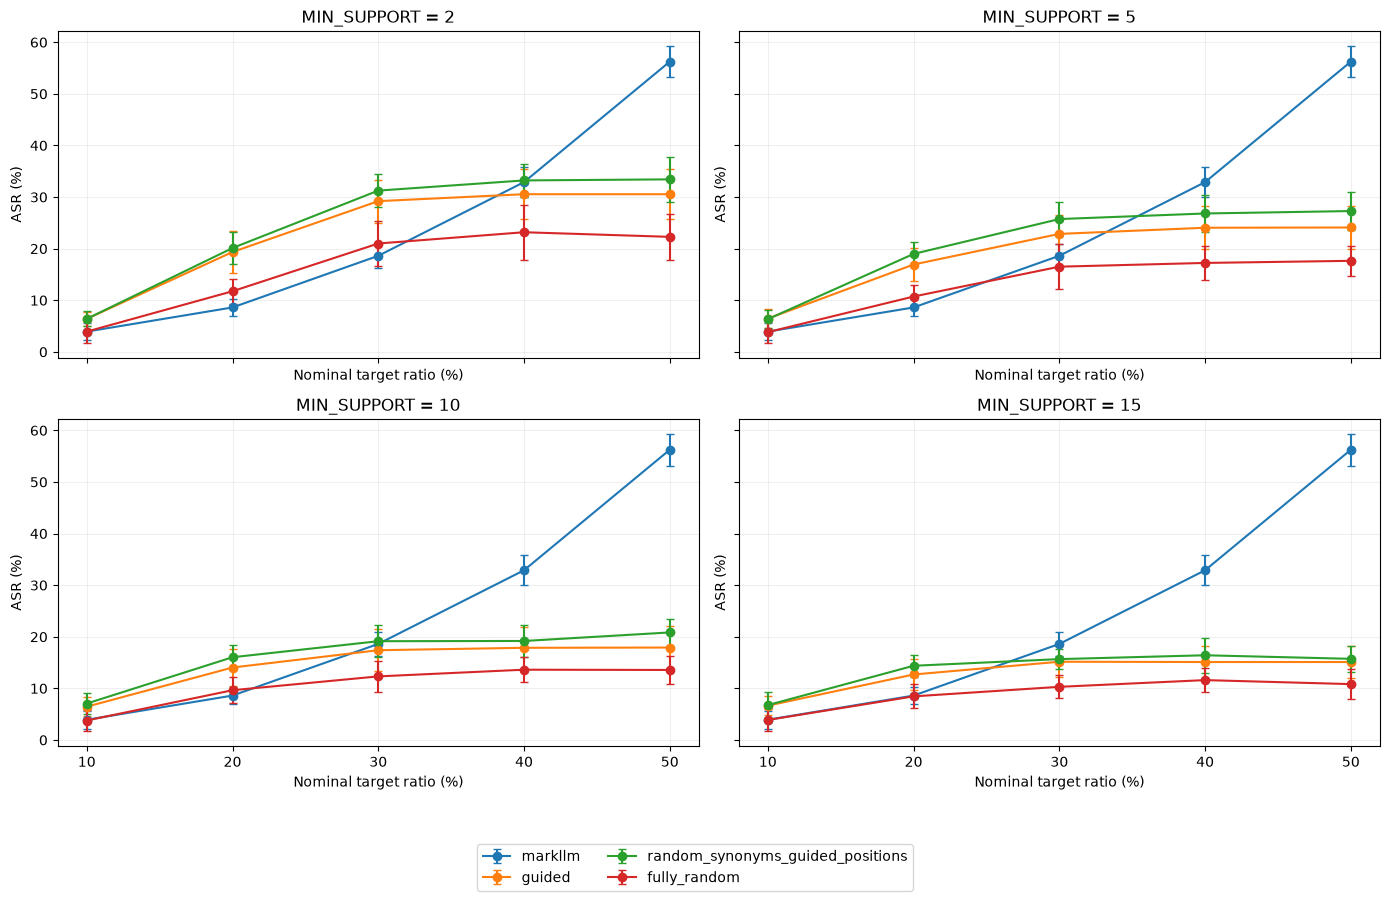

Plot: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/asr_by_support_and_ratio.png


In [13]:
try:
    import matplotlib.pyplot as plt
except (ImportError, OSError) as exc:
    print("Plot skipped: Matplotlib/Pillow is not available in this environment.")
    print("Reason:", str(exc)[:300])
else:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
    for ax, support in zip(axes.flat, MIN_SUPPORTS):
        part = stats_df[stats_df["min_support"] == support]
        for method in METHODS:
            sub = part[part["method"] == method].sort_values("ratio")
            ax.errorbar(sub["ratio"] * 100, sub["mean_asr"] * 100,
                        yerr=sub["std_asr"] * 100, marker="o", capsize=3,
                        label=method)
        ax.set_title(f"MIN_SUPPORT = {support}")
        ax.set_xticks([10, 20, 30, 40, 50])
        ax.set_xlabel("Nominal target ratio (%)")
        ax.set_ylabel("ASR (%)")
        ax.grid(alpha=0.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2)
    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plot_path = OUT_DIR / "asr_by_support_and_ratio.png"
    fig.savefig(plot_path, dpi=160)
    plt.show()
    print("Plot:", plot_path)

## 14. Interpretation checklist

1. **Primary question:** does lowering `MIN_SUPPORT` enlarge the dictionary and increase the **actual** editable share beyond ~19%?
2. **Quality tradeoff:** words supported by only 2–5 observations are much noisier. Larger coverage does **not** prove a better watermark-related signal.
3. **Matched budgets only within a given threshold/split/text:** custom attacks modify the same count for that comparison; as support changes, the number of modifications may change too.
4. **MarkLLM:** same nominal ratio, but effective edit count is unknown. Its saved notebook-05 results are reused, not recomputed.
5. **No test tuning:** because earlier tests already informed the support choices, report this threshold sweep as exploratory. A new untouched test set would be required for a confirmatory best-setting result.
6. **All outputs are local to the Mac** under `results/attacks/stealing_guided_v1_improvements/support_sweep_2_5_10_15/`. Source notebook files are unchanged.